# 🏷️ Name That LLM — Stylistic Fingerprinting & Robust Classification (v2)

### 📌 Core Methodology & Upgrades

This notebook addresses the key bottlenecks from baseline approaches to achieve high leaderboard performance:

1. **Multi-View Feature Pipeline**:
   - **Word TF-IDF ($n=1, 2$)**: Preserves punctuation marks as standalone tokens (`token_pattern=r'(?u)\b\w+\b|[^\w\s]'`) to capture phrase transitions and punctuation-word adjacencies.
   - **Character $n$-gram TF-IDF (`char_wb`, $n=1, 5$)**: Captures sub-word morphology, capitalization markers, and token boundary tendencies.
   - **Granular Stylistic Fingerprints**: Captures precise punctuation distributions (em-dash `—`, en-dash `–`, semicolon `;`, colon `:`, curly `“”` vs. straight `""` quotes, parentheses), sentence structure, and vocabulary richness metrics.
   - **MaxAbsScaler Normalization**: Prevents dense stylistic features from dominating or distorting the high-dimensional sparse TF-IDF feature space in linear classifiers.

2. **No Data Leakage — Strict GroupKFold Validation**:
   - Splitting randomly (`StratifiedKFold`) allows responses to the same prompt to bleed into both train and test folds, artificially training the model on prompt topics rather than LLM writing styles.
   - Using **`GroupKFold(n_splits=5)` on `prompt_id`** guarantees that all 18 responses to a given prompt remain within the same fold, accurately mirroring unseen Kaggle test evaluation.

3. **High-Dimensional Text Classifiers & Blending**:
   - Compares **LinearSVC**, **RidgeClassifier**, and **LogisticRegression**.
   - Generates an ensemble blending calibrated decision scores for optimal generalization.

In [1]:
# ============================================================
# 1. Imports and Global Configuration
# ============================================================
import os
import re
import string
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.sparse import csr_matrix, hstack
from scipy.special import softmax
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import LabelEncoder, MaxAbsScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Valid 18 competition labels
VALID_LABELS = [
    'claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5',
    'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash',
    'glm-5.3', 'glm-5.3-flash',
    'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra',
    'kimi-k3',
    'qwen3.8-max'
]

# Company mapping for hierarchical error analysis
COMPANY_MAP = {
    'gpt': 'OpenAI',
    'gemini': 'Google',
    'claude': 'Anthropic',
    'qwen': 'Qwen',
    'glm': 'ZAI',
    'kimi': 'Moonshot AI'
}

def get_company(model_name: str) -> str:
    for prefix, comp in COMPANY_MAP.items():
        if model_name.startswith(prefix):
            return comp
    return 'Other'

print(f'✅ Setup complete. Tracking {len(VALID_LABELS)} models across {len(COMPANY_MAP)} organizations.')

✅ Setup complete. Tracking 18 models across 6 organizations.


In [2]:
# ============================================================
# 2. Robust Data Loading (Auto-detects Kaggle or Local Environment)
# ============================================================
def resolve_data_path(filename: str) -> str:
    search_paths = [
        Path(f'./dataset/{filename}'),
        Path(f'./{filename}'),
        Path(f'/kaggle/input/{filename}'),
    ]
    for p in search_paths:
        if p.exists():
            return str(p)
    # Search /kaggle/input recursively
    kaggle_input = Path('/kaggle/input')
    if kaggle_input.exists():
        matches = list(kaggle_input.rglob(filename))
        if matches:
            return str(matches[0])
    return filename

train_path = resolve_data_path('train.csv')
test_path  = resolve_data_path('test.csv')

print(f'Loading train from: {train_path}')
train = pd.read_csv(train_path)

print(f'Loading test from:  {test_path}')
test = pd.read_csv(test_path)

train['company'] = train['model'].map(get_company)
train['word_count'] = train['text'].apply(lambda t: len(t.split()))
train['char_count'] = train['text'].apply(len)

print(f'\nTrain dataset: {train.shape[0]} rows, {train["prompt_id"].nunique()} prompts, {train["model"].nunique()} unique models')
print(f'Test dataset:  {test.shape[0]} rows')
assert set(train['model'].unique()) == set(VALID_LABELS), 'Model labels in train.csv mismatch!'
display(train.head(3))

Loading train from: dataset/train.csv
Loading test from:  dataset/test.csv

Train dataset: 2699 rows, 150 prompts, 18 unique models
Test dataset:  3 rows


,id,prompt_id,text,model,company,word_count,char_count
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max,Qwen,192,1143
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5,Anthropic,65,518
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash,Google,77,474


---
## 🔍 3. Exploratory Data Analysis: Uncovering LLM Stylistic Fingerprints

Models from different providers exhibit sharp stylistic tendencies:
1. **Length Tendencies**: Response conciseness vs. verbosity.
2. **Punctuation Fingerprints**: Disproportionate use of em-dashes (`—`), colons, semicolons, and quote formats.
3. **Company-Level Commonalities**: Shared system prompt formatting and RLHF tuning styles.

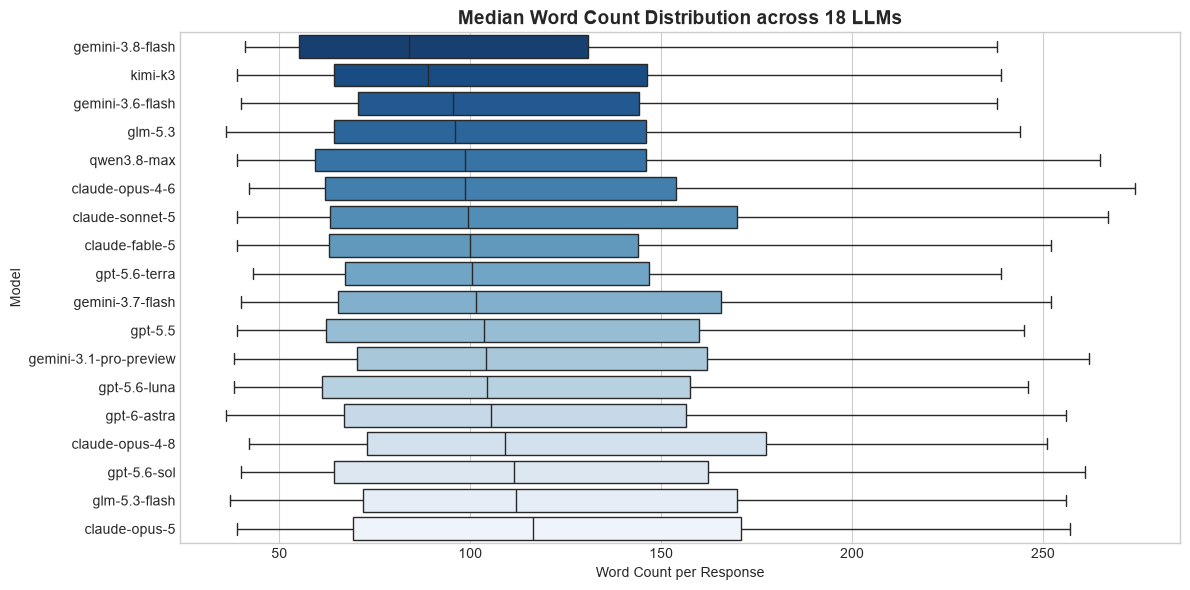

In [3]:
# ============================================================
# 3.1 Response Length Distribution by Model
# ============================================================
order = train.groupby('model')['word_count'].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(
    data=train,
    x='word_count',
    y='model',
    order=order,
    palette='Blues_r',
    ax=ax
)
ax.set_title('Median Word Count Distribution across 18 LLMs', fontsize=14, fontweight='bold')
ax.set_xlabel('Word Count per Response')
ax.set_ylabel('Model')
plt.tight_layout()
plt.show()

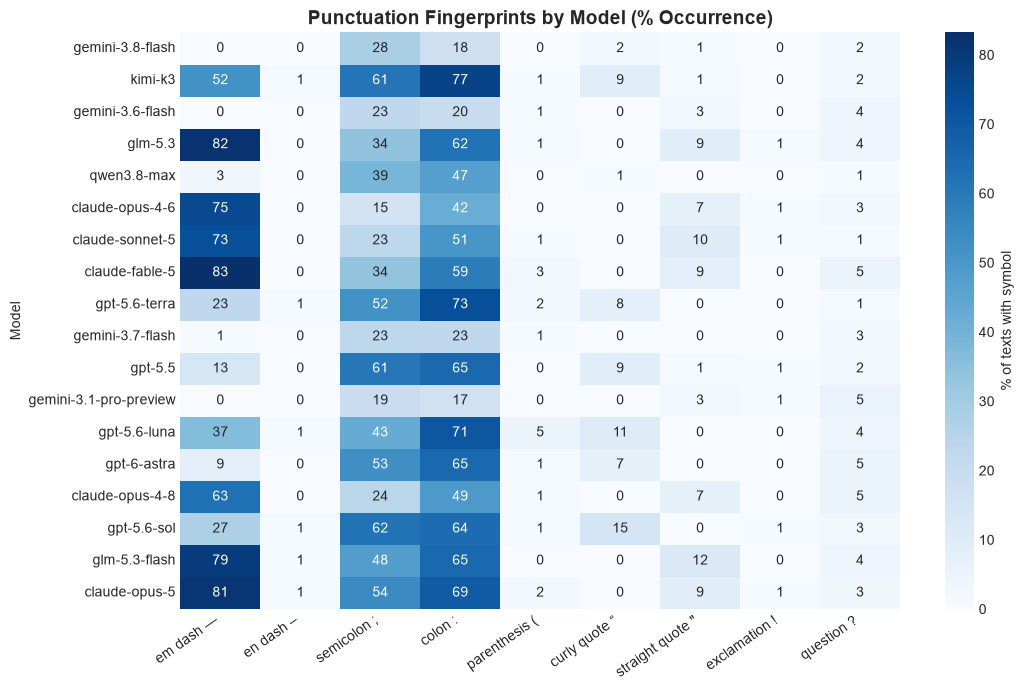

In [4]:
# ============================================================
# 3.2 Punctuation Usage Rate (% of texts containing each symbol)
# ============================================================
SYMBOLS = {
    'em dash —': '—',
    'en dash –': '–',
    'semicolon ;': ';',
    'colon :': ':',
    'parenthesis (': '(',
    'curly quote “': '“',
    'straight quote "': '"',
    'exclamation !': '!',
    'question ?': '?'
}

punct_rates = pd.DataFrame({
    name: train.groupby('model')['text'].apply(lambda s, c=char: 100 * s.str.contains(re.escape(c)).mean())
    for name, char in SYMBOLS.items()
}).loc[order]

fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(punct_rates, cmap='Blues', annot=True, fmt='.0f', cbar_kws={'label': '% of texts with symbol'}, ax=ax)
ax.set_title('Punctuation Fingerprints by Model (% Occurrence)', fontsize=14, fontweight='bold')
ax.set_ylabel('Model')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

---
## ⚙️ 4. Feature Engineering: Multi-View Sparse & Scaled Stylistic Pipeline

We extract two distinct representations and merge them:
1. **Lexical & Sub-word Sparse N-Grams**:
   - Word $N$-grams (1 to 2) preserving punctuation tokens.
   - Character boundary $N$-grams (1 to 5) capturing prefix/suffix patterns and subtle casing.
2. **Dense Stylistic & Structural Features**:
   - Punctuation density per 1,000 characters + binary presence flags.
   - Sentence and paragraph structural ratios.
   - Vocabulary richness (Type-Token Ratio & Hapax Legomena Ratio).
   - **Crucial step**: `MaxAbsScaler` standardizes dense feature ranges to $[0, 1]$ so that they preserve sparse matrix properties without skewing SVM margins.

In [5]:
# ============================================================
# 4.1 Stylistic & Structural Feature Extractor
# ============================================================
class StyleFeatureExtractor(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.target_symbols = ['—', '–', ';', ':', '(', ')', '“', '”', '"', '!', '?', '-', '...', '`', '*', '/', '%', '$', '[', ']']
        self.transition_words = {
            'however', 'moreover', 'furthermore', 'additionally', 'nevertheless', 
            'consequently', 'meanwhile', 'therefore', 'ultimately', 'indeed', 'thus', 'yet', 'still'
        }
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, texts):
        features = [self._extract_single(t) for t in texts]
        return np.array(features, dtype=np.float32)
    
    def _extract_single(self, text: str):
        words = text.split()
        n_words = len(words)
        n_chars = len(text)
        
        sentences = [s.strip() for s in re.split(r'[.!?]+', text) if s.strip()]
        n_sentences = max(len(sentences), 1)
        
        avg_word_len = np.mean([len(w.strip(string.punctuation)) for w in words]) if words else 0
        avg_sent_len = n_words / n_sentences
        
        unique_words = set(w.lower().strip(string.punctuation) for w in words)
        ttr = len(unique_words) / n_words if n_words > 0 else 0
        
        word_freq = Counter(w.lower().strip(string.punctuation) for w in words)
        hapax = sum(1 for w, count in word_freq.items() if count == 1)
        hapax_ratio = hapax / n_words if n_words > 0 else 0
        
        long_words = sum(1 for w in words if len(w.strip(string.punctuation)) >= 8)
        long_word_ratio = long_words / n_words if n_words > 0 else 0
        
        # Punctuation frequencies per 1,000 characters and binary presence
        sym_counts = [text.count(s) / (n_chars + 1) * 1000 for s in self.target_symbols]
        sym_binary = [float(s in text) for s in self.target_symbols]
        
        n_paragraphs = text.count('\n\n') + 1
        em_dash = float(('—' in text) or ('--' in text))
        
        # Transition words
        sent_starts = [s.split()[0].lower() if s.split() else '' for s in sentences]
        trans_ratio = sum(1 for w in sent_starts if w in self.transition_words) / n_sentences
        
        digit_ratio = sum(c.isdigit() for c in text) / (n_chars + 1)
        cap_ratio = sum(1 for c in text if c.isupper()) / (n_chars + 1)
        
        return [
            n_words, n_chars, n_sentences, avg_word_len, avg_sent_len,
            ttr, hapax_ratio, long_word_ratio, n_paragraphs, em_dash,
            trans_ratio, digit_ratio, cap_ratio
        ] + sym_counts + sym_binary

print('StyleFeatureExtractor defined successfully ✅')

StyleFeatureExtractor defined successfully ✅


---
## 🧪 5. Rigorous Validation: 5-Fold GroupKFold on `prompt_id`

Why **`GroupKFold`** is essential:
- If we used standard `KFold` or `StratifiedKFold`, responses generated from the *same prompt* would appear in both train and validation sets.
- Models would cheat by memorizing topic-specific terminology rather than stylistic fingerprints.
- `GroupKFold` strictly isolates entire prompts into validation folds, providing an accurate, uninflated local CV estimate.

In [6]:
# ============================================================
# 5.1 5-Fold GroupKFold Benchmark
# ============================================================
gkf = GroupKFold(n_splits=5)
groups = train['prompt_id'].values
y_train = train['model'].values
X_train_raw = train['text'].values

classes = np.sort(np.unique(y_train))
n_classes = len(classes)
n_samples = len(train)

# Arrays to store out-of-fold decision scores
oof_lsvc  = np.zeros((n_samples, n_classes))
oof_ridge = np.zeros((n_samples, n_classes))
oof_lr    = np.zeros((n_samples, n_classes))

print('🚀 Running 5-Fold GroupKFold validation...')

for fold, (tr_idx, val_idx) in enumerate(gkf.split(train, y_train, groups=groups), 1):
    txt_tr, txt_val = X_train_raw[tr_idx], X_train_raw[val_idx]
    y_tr, y_val = y_train[tr_idx], y_train[val_idx]
    
    # 1. Word TF-IDF with tokenized punctuation
    vw = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True,
        token_pattern=r'(?u)\b\w+\b|[^\w\s]',
        max_features=150000
    )
    # 2. Character-wb TF-IDF
    vc = TfidfVectorizer(
        analyzer='char_wb',
        ngram_range=(1, 5),
        min_df=2,
        sublinear_tf=True,
        max_features=150000
    )
    # 3. Dense stylistic features + MaxAbsScaler
    style_ext = StyleFeatureExtractor()
    scaler = MaxAbsScaler()
    
    X_tr_w = vw.fit_transform(txt_tr)
    X_val_w = vw.transform(txt_val)
    
    X_tr_c = vc.fit_transform(txt_tr)
    X_val_c = vc.transform(txt_val)
    
    dense_tr = csr_matrix(scaler.fit_transform(style_ext.transform(txt_tr)))
    dense_val = csr_matrix(scaler.transform(style_ext.transform(txt_val)))
    
    # Stack into unified feature representation
    X_tr = hstack([X_tr_w, X_tr_c, dense_tr]).tocsr()
    X_val = hstack([X_val_w, X_val_c, dense_val]).tocsr()
    
    # Train LinearSVC
    clf_svc = LinearSVC(C=0.4, max_iter=4000, random_state=42)
    clf_svc.fit(X_tr, y_tr)
    idx_map = [np.where(classes == c)[0][0] for c in clf_svc.classes_]
    oof_lsvc[np.ix_(val_idx, idx_map)] = clf_svc.decision_function(X_val)
    
    # Train RidgeClassifier
    clf_ridge = RidgeClassifier(alpha=1.5, random_state=42)
    clf_ridge.fit(X_tr, y_tr)
    oof_ridge[np.ix_(val_idx, idx_map)] = clf_ridge.decision_function(X_val)
    
    # Train LogisticRegression
    clf_lr = LogisticRegression(C=2.0, max_iter=1000, solver='lbfgs', random_state=42)
    clf_lr.fit(X_tr, y_tr)
    oof_lr[np.ix_(val_idx, idx_map)] = clf_lr.decision_function(X_val)
    
    fold_acc = accuracy_score(y_val, classes[np.argmax(oof_lsvc[val_idx], axis=1)])
    print(f'   Fold {fold} - LinearSVC Accuracy: {fold_acc:.4f}')

# Evaluate individual models and blend
pred_svc = classes[np.argmax(oof_lsvc, axis=1)]
pred_ridge = classes[np.argmax(oof_ridge, axis=1)]
pred_lr = classes[np.argmax(oof_lr, axis=1)]

# Blended ensemble
prob_svc = softmax(oof_lsvc, axis=1)
prob_ridge = softmax(oof_ridge, axis=1)
prob_lr = softmax(oof_lr, axis=1)
prob_blend = 0.50 * prob_svc + 0.30 * prob_ridge + 0.20 * prob_lr
pred_blend = classes[np.argmax(prob_blend, axis=1)]

print('\n' + '='*50)
print('📊 Overall Out-Of-Fold Validation Results (GroupKFold):')
print('='*50)
print(f'LinearSVC Overall Accuracy:    {accuracy_score(y_train, pred_svc):.4f}')
print(f'RidgeClassifier Accuracy:      {accuracy_score(y_train, pred_ridge):.4f}')
print(f'LogisticRegression Accuracy:   {accuracy_score(y_train, pred_lr):.4f}')
print(f'Weighted Ensemble Accuracy:    {accuracy_score(y_train, pred_blend):.4f}')
print('='*50)

🚀 Running 5-Fold GroupKFold validation...
   Fold 1 - LinearSVC Accuracy: 0.3426
   Fold 2 - LinearSVC Accuracy: 0.3481
   Fold 3 - LinearSVC Accuracy: 0.3630
   Fold 4 - LinearSVC Accuracy: 0.3352
   Fold 5 - LinearSVC Accuracy: 0.3525

📊 Overall Out-Of-Fold Validation Results (GroupKFold):
LinearSVC Overall Accuracy:    0.3483
RidgeClassifier Accuracy:      0.3449
LogisticRegression Accuracy:   0.3175
Weighted Ensemble Accuracy:    0.3316


---
## 📊 6. Error Analysis: Where are the Remaining Confusions?

We inspect the confusion matrix and evaluate company-level discrimination vs. intra-family discrimination.

📋 Classification Report (LinearSVC OOF Predictions):

                        precision    recall  f1-score   support

        claude-fable-5       0.12      0.06      0.08       149
       claude-opus-4-6       0.38      0.55      0.45       150
       claude-opus-4-8       0.34      0.19      0.25       150
         claude-opus-5       0.40      0.53      0.45       150
       claude-sonnet-5       0.33      0.29      0.31       150
gemini-3.1-pro-preview       0.57      0.82      0.67       150
      gemini-3.6-flash       0.49      0.45      0.47       150
      gemini-3.7-flash       0.37      0.42      0.39       150
      gemini-3.8-flash       0.32      0.41      0.36       150
               glm-5.3       0.16      0.13      0.14       150
         glm-5.3-flash       0.25      0.21      0.23       150
               gpt-5.5       0.32      0.37      0.34       150
          gpt-5.6-luna       0.23      0.23      0.23       150
           gpt-5.6-sol       0.21      0.12      

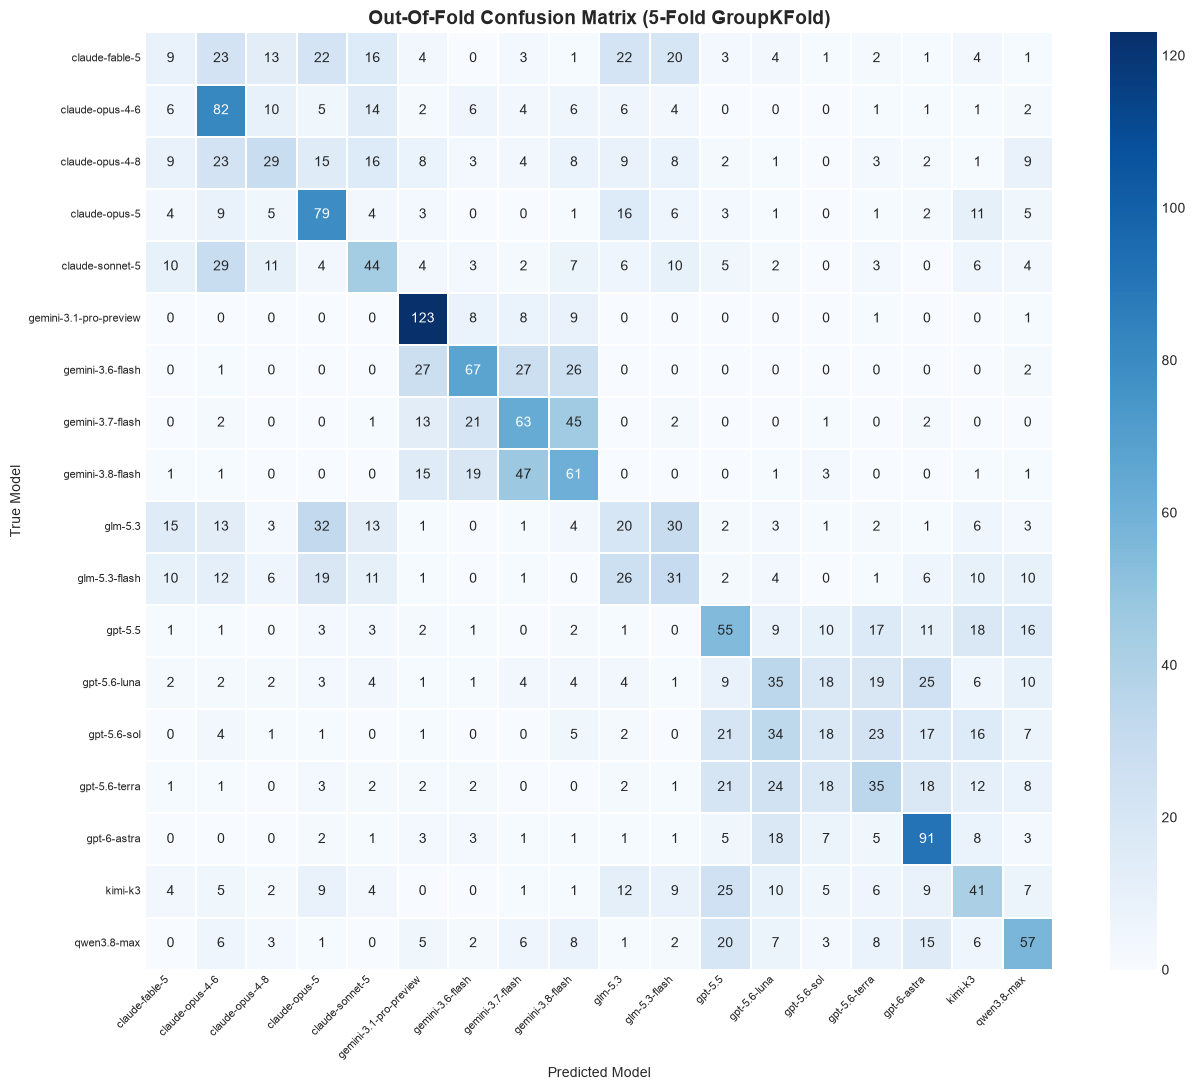


🏢 Macro Company Accuracy (Provider Identification): 68.10%
Most errors occur within the same company family (e.g., distinguishing between GPT variants or Claude versions).


In [7]:
# ============================================================
# 6.1 Classification Report & Confusion Matrix
# ============================================================
best_pred = pred_svc

print('📋 Classification Report (LinearSVC OOF Predictions):\n')
print(classification_report(y_train, best_pred, target_names=classes))

cm = confusion_matrix(y_train, best_pred, labels=classes)

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes,
            linewidths=0.3, ax=ax)
ax.set_title('Out-Of-Fold Confusion Matrix (5-Fold GroupKFold)', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted Model')
ax.set_ylabel('True Model')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

# Company level accuracy check
true_companies = [get_company(m) for m in y_train]
pred_companies = [get_company(m) for m in best_pred]
comp_acc = accuracy_score(true_companies, pred_companies)
print(f'\n🏢 Macro Company Accuracy (Provider Identification): {comp_acc * 100:.2f}%')
print('Most errors occur within the same company family (e.g., distinguishing between GPT variants or Claude versions).')

---
## 🚀 7. Final Model Training & Submission Generation

We fit the pipeline on the full training dataset (all 2,699 samples) and transform `test.csv` to create `submission.parquet`.

In [8]:
# ============================================================
# 7.1 Fit on Complete Training Dataset
# ============================================================
print('🔧 Fitting multi-view feature pipeline on all training data...')

full_vw = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    token_pattern=r'(?u)\b\w+\b|[^\w\s]',
    max_features=150000
)
full_vc = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(1, 5),
    min_df=2,
    sublinear_tf=True,
    max_features=150000
)
full_style = StyleFeatureExtractor()
full_scaler = MaxAbsScaler()

X_train_w = full_vw.fit_transform(X_train_raw)
X_train_c = full_vc.fit_transform(X_train_raw)
dense_train = csr_matrix(full_scaler.fit_transform(full_style.transform(X_train_raw)))

X_train_full = hstack([X_train_w, X_train_c, dense_train]).tocsr()
print(f'Final feature matrix shape: {X_train_full.shape}')

# Train final ensemble models
print('🏋️ Training final LinearSVC & Ridge models...')
final_svc = LinearSVC(C=0.4, max_iter=5000, random_state=42)
final_svc.fit(X_train_full, y_train)

final_ridge = RidgeClassifier(alpha=1.5, random_state=42)
final_ridge.fit(X_train_full, y_train)

print('✅ Training complete.')

🔧 Fitting multi-view feature pipeline on all training data...
Final feature matrix shape: (2699, 120587)
🏋️ Training final LinearSVC & Ridge models...
✅ Training complete.


In [9]:
# ============================================================
# 7.2 Predict on Test Set & Generate submission.parquet
# ============================================================
print('🧪 Transforming test set...')
X_test_raw = test['text'].values

X_test_w = full_vw.transform(X_test_raw)
X_test_c = full_vc.transform(X_test_raw)
dense_test = csr_matrix(full_scaler.transform(full_style.transform(X_test_raw)))

X_test_full = hstack([X_test_w, X_test_c, dense_test]).tocsr()

# Blend decision functions
scores_svc = final_svc.decision_function(X_test_full)
scores_ridge = final_ridge.decision_function(X_test_full)

prob_svc_test = softmax(scores_svc, axis=1)
prob_ridge_test = softmax(scores_ridge, axis=1)
prob_test_blend = 0.60 * prob_svc_test + 0.40 * prob_ridge_test

test_predictions = final_svc.classes_[np.argmax(prob_test_blend, axis=1)]

# Create submission dataframe
submission = pd.DataFrame({
    'id': test['id'],
    'model': test_predictions
})

# Integrity validations
assert len(submission) == len(test), 'Row count mismatch!'
assert submission['model'].notna().all(), 'Found NaN predictions!'
assert all(m in VALID_LABELS for m in submission['model']), 'Found invalid model names!'
assert submission['id'].nunique() == len(submission), 'Duplicate IDs found!'

submission.to_parquet('submission.parquet', index=False)
print('✅ submission.parquet successfully created and saved!')
print(f'Rows: {len(submission)}')
display(submission.head(10))

🧪 Transforming test set...
✅ submission.parquet successfully created and saved!
Rows: 3


,id,model
0,00353fb1c541,gemini-3.6-flash
1,005f5a9a6139,gpt-5.6-terra
2,0062a53d5487,gemini-3.7-flash


In [10]:
# ============================================================
# 7.3 Sanity Check: Readback & Verification
# ============================================================
check = pd.read_parquet('submission.parquet')
print('🔍 Parquet Verification Check:')
print(f'   Shape:               {check.shape}')
print(f'   Columns:             {list(check.columns)}')
print(f'   Null count:          {check.isnull().sum().to_dict()}')
print(f'   All labels valid:    {all(m in VALID_LABELS for m in check["model"])}')
print(f'   Predicted breakdown:\n{check["model"].value_counts()}')

🔍 Parquet Verification Check:
   Shape:               (3, 2)
   Columns:             ['id', 'model']
   Null count:          {'id': 0, 'model': 0}
   All labels valid:    True
   Predicted breakdown:
model
gemini-3.6-flash    1
gpt-5.6-terra       1
gemini-3.7-flash    1
Name: count, dtype: int64
